In [ ]:
import torch
print(torch.cuda.is_available())
!nvidia-smi

True
Tue Sep 22 00:47:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+

In [ ]:
!pip install -q diffusers transformers accelerate safetensors scikit-image

In [ ]:
import numpy as np, torch
from PIL import Image, ImageDraw, ImageFilter
from transformers import SamModel, SamProcessor

REAL = "/content/corpus/real/par1.png"      # corpus/real/guatemala_0058_Hillary_Clinton_with_Alvaro_Colom_2010.jpg
CALIDAD_JPEG = 88      # calidad de su pareja real (metadata_real.csv)
SEMILLA = 22500

img = Image.open(REAL).convert("RGB")
W, H = img.size

sam = SamModel.from_pretrained("facebook/sam-vit-base").to("cuda")
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")

def segmentar(caja):
    inp = sam_proc(img, input_boxes=[[caja]], return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = sam(**inp)
    masks = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inp["original_sizes"].cpu(), inp["reshaped_input_sizes"].cpu())
    mejor = out.iou_scores[0, 0].argmax().item()
    return masks[0][0, mejor].numpy()

def rect(caja):
    m = np.zeros((H, W), bool)
    x0, y0, x1, y1 = caja
    m[y0:y1, x0:x1] = True
    return m

def elipse(caja):
    m = Image.new("L", (W, H), 0)
    ImageDraw.Draw(m).ellipse(caja, fill=255)
    return np.asarray(m) > 0

def preparar(m, proteger=()):
    """Dilata ~10 px para cubrir bordes y luego quita las zonas protegidas."""
    dil = np.asarray(Image.fromarray((m * 255).astype(np.uint8)).filter(ImageFilter.MaxFilter(21))) > 0
    for p in proteger:
        dil &= ~p
    return dil

CARA  = rect([0, 0, W, 310])          # nada por encima del cuello
MANOS = rect([555, 520, 665, 605])

NIVELES = {
    "obvio": dict(
        mascara=preparar(segmentar([530, 300, 765, 768]), [CARA, MANOS]),
        area=(5, 20), delta_e=(25, 999),
        prompt="a woman wearing a bright red suit, red blazer and red trousers, "
               "photorealistic photograph, natural indoor lighting",
        negativo="dark suit, gray suit, black suit, navy suit, cartoon, distorted, "
                 "blurry, extra limbs, extra fingers"),
    "normal": dict(
        mascara=preparar(rect([548, 470, 700, 630]), [CARA]),
        area=(2, 8), delta_e=(10, 25),
        prompt="a woman holding a closed dark blue leather folder with both hands in front of her, "
               "photorealistic photograph, natural indoor lighting",
        negativo="empty hands, deformed hands, extra fingers, cartoon, distorted, blurry"),
    "sutil": dict(
        mascara=preparar(elipse([678, 308, 722, 352])),
        area=(0.1, 2), delta_e=(3, 10),
        prompt="a small silver american flag lapel pin on a dark gray blazer, photorealistic, detailed",
        negativo="gold brooch, round gold pin, cartoon, blurry, distorted"),
}

del sam
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

obvio  área  9.67 %  (rango 5–20 %)
normal área  3.50 %  (rango 2–8 %)
sutil  área  0.43 %  (rango 0.1–2 %)


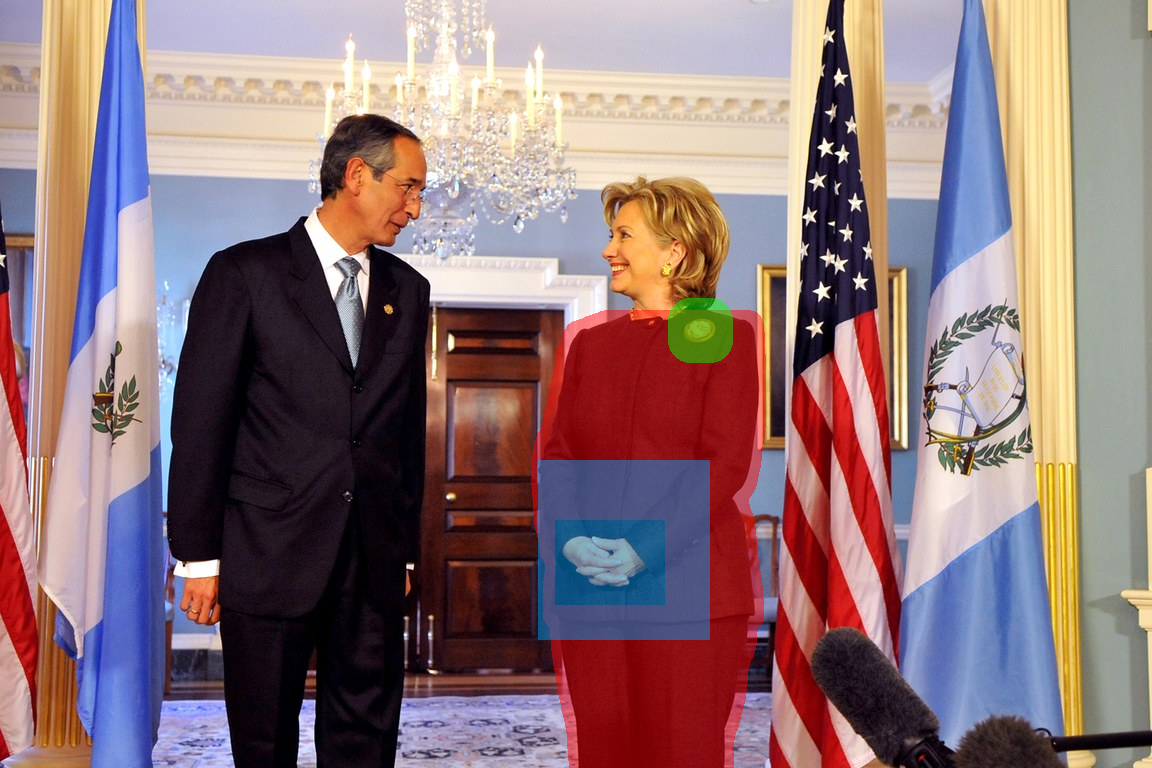

In [ ]:
vista = img.copy()
colores = {"obvio": (255, 0, 0), "normal": (0, 160, 255), "sutil": (0, 255, 0)}
for nombre, cfg in NIVELES.items():
    capa = Image.new("RGB", img.size, colores[nombre])
    vista = Image.composite(capa, vista, Image.fromarray((cfg["mascara"] * 120).astype(np.uint8)))
    print(f"{nombre:6s} área {cfg['mascara'].mean()*100:5.2f} %  (rango {cfg['area'][0]}–{cfg['area'][1]} %)")
vista.save("revision_mascaras.png")
display(vista)

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

obvio  | área  9.67% OK | cambio visible  5.36% OK | fuera de máscara: 0


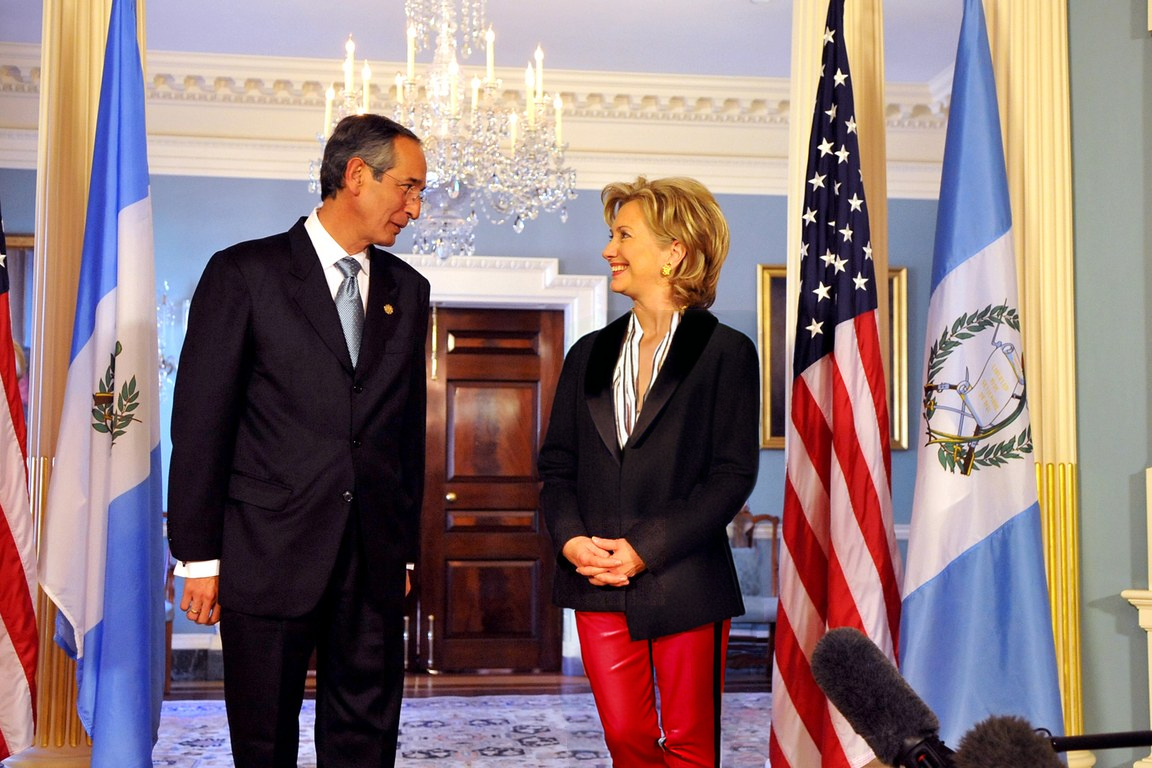

  0%|          | 0/39 [00:00<?, ?it/s]

normal | área  3.50% OK | cambio visible  1.14% OK | fuera de máscara: 0


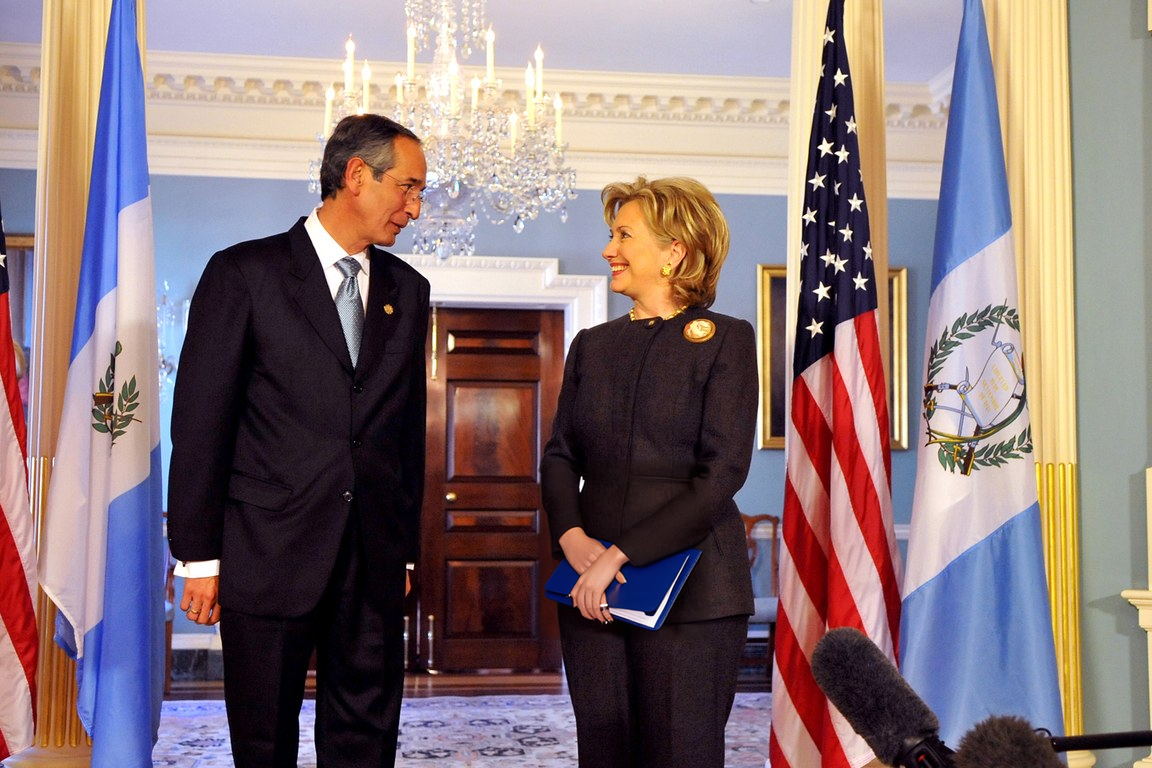

  0%|          | 0/39 [00:00<?, ?it/s]

sutil  | área  0.43% OK | cambio visible  0.12% OK | fuera de máscara: 0


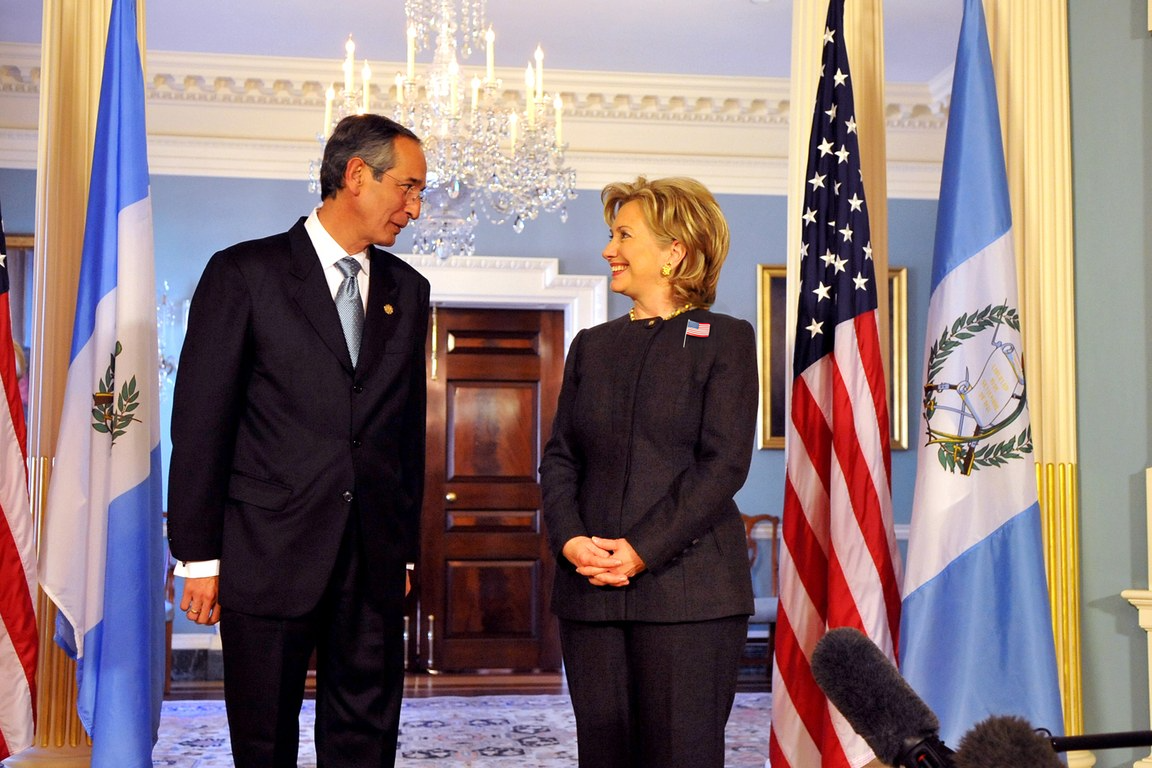

In [ ]:
from diffusers import AutoPipelineForInpainting
from skimage.color import rgb2lab, deltaE_ciede2000

pipe = AutoPipelineForInpainting.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1", torch_dtype=torch.float16).to("cuda")

real_np  = np.asarray(img)
lab_real = rgb2lab(real_np)

RANGO_CAMBIO = {"obvio": (1.5, 20), "normal": (0.4, 1.5), "sutil": (0.05, 0.4)}

for nombre, cfg in NIVELES.items():
    dura     = cfg["mascara"]
    mask_pil = Image.fromarray((dura * 255).astype(np.uint8))
    suave    = mask_pil.filter(ImageFilter.GaussianBlur(3))

    salida = pipe(
        prompt=cfg["prompt"], negative_prompt=cfg["negativo"],
        image=img, mask_image=mask_pil, width=W, height=H,
        num_inference_steps=40, guidance_scale=11.0, strength=0.99,
        padding_mask_crop=32,
        generator=torch.Generator("cuda").manual_seed(SEMILLA),
    ).images[0]
    compuesta = pipe.image_processor.apply_overlay(suave, img, salida).convert("RGB")
    comp_np   = np.asarray(compuesta)

    # --- validación ---
    area   = dura.mean() * 100
    cambio = (deltaE_ciede2000(lab_real, rgb2lab(comp_np)) > 10).mean() * 100
    fuera  = np.abs(comp_np.astype(int) - real_np.astype(int))[np.asarray(suave) == 0].max()
    ok_a   = cfg["area"][0] <= area <= cfg["area"][1]
    ok_c   = RANGO_CAMBIO[nombre][0] <= cambio <= RANGO_CAMBIO[nombre][1]

    # --- guardado ---
    compuesta.save(f"par1_compuesta_{nombre}.png")              # sin pérdida, para análisis
    compuesta.save(f"par1_{nombre}.jpg", quality=CALIDAD_JPEG)  # versión del corpus
    mask_pil.save(f"par1_mascara_{nombre}.png")

    print(f"{nombre:6s} | área {area:5.2f}% {'OK' if ok_a else 'FUERA DE RANGO'}"
          f" | cambio visible {cambio:5.2f}% {'OK' if ok_c else 'FUERA DE RANGO'}"
          f" | fuera de máscara: {fuera}")
    display(compuesta)